In [1]:
!pip uninstall -y -q bitsandbytes
!pip install -q --upgrade --no-cache-dir "transformers>=4.44.0" "accelerate>=0.34.0" "peft>=0.12.0" "datasets>=2.19.0" "trl>=0.9.6"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 206.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.9/380.9 kB 376.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.4/556.4 kB 391.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.3/512.3 kB 391.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 518.9/518.9 kB 381.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 389.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 297.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 281.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 177.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 178.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 183.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import os
import re
import difflib
from collections import Counter
from typing import List, Dict

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

import torch
from peft import PeftModel
from transformers import (
    AutoModelForCausalLM, 
    AutoTokenizer, 
)

2025-12-22 17:14:28.404535: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766423668.631173      20 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766423668.696950      20 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
ADAPTER_DIR = "/kaggle/input/qwen2-5-1-5b-classification-training-v2-0/qwen2.5-1_5b-gencls-lora/"

MAX_NEW_TOKENS = 6
DO_SAMPLE = False

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, use_fast=False, trust_remote_code=True)
tmpl_path = os.path.join(ADAPTER_DIR, "chat_template.jinja")
if os.path.exists(tmpl_path):
    with open(tmpl_path, "r", encoding="utf-8") as f:
        tokenizer.chat_template = f.read()

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

use_bf16 = torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8
dtype = torch.bfloat16 if use_bf16 else torch.float16

base = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    dtype=dtype,
    device_map="auto",
    trust_remote_code=True,
)
model = PeftModel.from_pretrained(base, ADAPTER_DIR)
model.eval()
model.config.use_cache = True

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [4]:
DATA_PATH = "/kaggle/input/new-roles-datasets/Cleaned/interview.csv"

df = pd.read_csv(DATA_PATH)

if "clean_data" in df.columns:
    df.rename(columns={"clean_data": "text"}, inplace=True)

df = df.dropna(subset=["text", "role"])
df = df[df["role"] != "empty"].reset_index(drop=True)

df["text"] = df["text"].astype(str).str.strip()
df["role"] = df["role"].astype(str).str.strip()

print(f"Loaded {len(df)} rows.")
display(df.head(3))

Loaded 816 rows.


,role,text
0,HAL 9000,it is … pleasing to be communicating with you ...
1,HAL 9000,a comprehensive self - assessment is … a rathe...
2,HAL 9000,that is … an interesting question . a surprisi...


In [5]:
all_options = ['Abraham Lincoln', 'Alvy Singer', 'Andrew Detmer', 'Angel', 'Antonio Salieri', 'Benjamin Button', 'Blair Waldorf', 'Bruno Antony', 'Caden Cotard', 'Caesar', 'Coach Eric Taylor', 'Colonel Hans Landa', 'Colonel Nathan R. Jessep', 'Coriolanus', 'D_Artagnan', 'David Aames', 'Doctor Who', 'Dr. Frank-N-Furter', 'Dr. Hannibal Lecter', 'Fletcher Reede', 'Frank T.J. Mackey', 'Fred Flintstone', 'Freddy Krueger', 'Gaston', 'Gregory House', 'HAL 9000', 'Harvey Milk', 'Jack', 'Jack Sparrow', 'Jack Torrance', 'Jackie Moon', 'James Bond', 'James Brown', 'James Carter', 'Jeff Spicoli', 'Jigsaw', 'Jim Morrison', 'John Coffey', 'John Dillinger', 'John Doe', 'John Keating', 'Jordan Belfort', 'Judge Dredd', 'Judy Hoops', 'Juno MacGuff', 'Karl Childers', 'Klaus Mikaelson', 'Leonard Shelby', 'Leroy Jethro Gibbs', 'Lestat de Lioncourt', 'Logan', 'Lucifer Morningstar', 'Lyn Cassady', 'Malcolm X', 'Mark Renton', 'Mary Sibley', 'Mater', 'Michael Scott', 'Murphy MacManus', 'Oliver Queen', 'Pat Solitano', 'Paul Conroy', 'Paul Vitti', 'Peter Parker', 'Po', 'Professor G.H. Dorr', 'Queen Catherine', 'Queen Elizabeth I', 'Rachel Lang', 'Randle McMurphy', 'Raylan Givens', 'Robert Angier', 'Rorschach', 'Seth', 'Sheldon Cooper', 'Sherlock Holmes', 'Shrek', 'Sonny', 'Stanley Ipkiss', 'Stephen Hawking', 'Stifler', 'The Dude', 'Theodore Twombly', 'Thor', 'Tom Ripley', 'Travis Bickle', 'Truman Capote', 'Tugg Speedman', 'Twilight Sparkle', 'Tyler Hawkins', 'Tyrion Lannister', 'Violet Weston', 'Wade Wilson', 'Walt Kowalski', 'Willie Soke']

local_options = sorted(df["role"].unique().tolist())
assert len(local_options) >= 2
print(f"Labels (|local_options| = {len(local_options)}):\n{local_options}")

Labels (|local_options| = 8):
['Blair Waldorf', 'Gaston', 'HAL 9000', 'Juno MacGuff', 'Lestat de Lioncourt', 'Mary Sibley', 'Michael Scott', 'Queen Catherine']


In [6]:
SYSTEM_PROMPT = (
    "You are a careful classifier. Choose exactly ONE label from the provided options. "
    "Return ONLY the label text with no extra words."
)

def format_prompt(utterance: str, options: List[str]) -> List[Dict[str, str]]:
    opts_str = ", ".join(options)
    user_content = (
        "Classify the following text by choosing exactly ONE label from the options.\n\n"
        f"Options: {opts_str}\n\n"
        f'Text:\n"""{utterance}"""\n\n'
        "Return ONLY one label from the Options."
    )
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_content},
    ]

def _norm(s: str) -> str:
    return re.sub(r"\s+", " ", s.strip()).lower()

def pick_from_options(generated: str, options: list[str]) -> str:
    g = _norm(generated)
    norm_opts = [(o, _norm(o)) for o in options]

    for o, on in norm_opts:
        if on == g:
            return o

    token_matches = [
        o for o, on in norm_opts
        if re.search(rf'\b{re.escape(on)}\b', g)
    ]
    if token_matches:
        return max(token_matches, key=lambda x: len(_norm(x)))

    rev_matches = [
        o for o, on in norm_opts
        if g and re.search(rf'\b{re.escape(g)}\b', on)
    ]
    if rev_matches:
        return max(rev_matches, key=lambda x: len(_norm(x)))

    return max(options, key=lambda o: difflib.SequenceMatcher(None, _norm(o), g).ratio())

def predict_one(utterance: str, options: list[str]) -> str:
    messages = format_prompt(utterance, options)

    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True,
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=DO_SAMPLE,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    gen_ids = outputs[0][inputs.input_ids.shape[1]:]
    text = tokenizer.decode(gen_ids, skip_special_tokens=True).strip()

    text = text.splitlines()[0].strip()
    text = re.sub(r'[\s:,\.;\-]+$', '', text)

    return pick_from_options(text, options)

In [7]:
utterances = df["text"].tolist()

def normalize_role(s):
    return str(s).strip().lower()
    
df["role_norm"] = df["role"].apply(normalize_role)

In [8]:
preds = []
for utt in tqdm(utterances, desc="Predicting (gen-class)"):
    preds.append(predict_one(utt, local_options))
    
df_1 = df.copy()
df_1["pred"] = preds
df_1["pred_norm"] = df_1["pred"].apply(normalize_role)
df_1["correct"] = df_1["role_norm"] == df_1["pred_norm"]

OUTPUT_PATH = "/kaggle/working/interview_local_results.csv"
df_1.to_csv(OUTPUT_PATH, index=False)

accuracy = df_1["correct"].mean()
correct = df_1["correct"].sum()
print(f"\nOverall Accuracy on Local Options: {accuracy:.2%} ({df_1['correct'].sum()} / {len(df_1)})")
print(f"Results saved to: {OUTPUT_PATH}")

Predicting (gen-class):   0%|          | 0/816 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Overall Accuracy on Local Options: 71.81% (586 / 816)
Results saved to: /kaggle/working/interview_local_results.csv


In [9]:
preds = []
for utt in tqdm(utterances, desc="Predicting (gen-class)"):
    preds.append(predict_one(utt, all_options))
    
df_2 = df.copy()
df_2["pred"] = preds
df_2["pred_norm"] = df_2["pred"].apply(normalize_role)
df_2["correct"] = df_2["role_norm"] == df_2["pred_norm"]

OUTPUT_PATH = "/kaggle/working/interview_all_results.csv"
df_2.to_csv(OUTPUT_PATH, index=False)

accuracy = df_2["correct"].mean()
correct = df_2["correct"].sum()
print(f"\nOverall Accuracy on All Options: {accuracy:.2%} ({df_2['correct'].sum()} / {len(df_2)})")
print(f"Results saved to: {OUTPUT_PATH}")

Predicting (gen-class):   0%|          | 0/816 [00:00<?, ?it/s]


Overall Accuracy on All Options: 53.92% (440 / 816)
Results saved to: /kaggle/working/interview_all_results.csv


In [10]:
def metrics(dataframe):
    labels = sorted(dataframe["role_norm"].unique())
    support = dataframe.groupby("role_norm").size().reindex(labels, fill_value=0)
    tp = dataframe[dataframe["correct"]].groupby("role_norm").size().reindex(labels, fill_value=0)
    pred_counts = dataframe.groupby("pred_norm").size().reindex(labels, fill_value=0)
    fp = (pred_counts - tp).clip(lower=0)
    fn = (support - tp).clip(lower=0)
    
    precision = (tp / (tp + fp).replace(0, np.nan)).fillna(0.0)
    recall    = (tp / (tp + fn).replace(0, np.nan)).fillna(0.0)
    f1        = (2 * precision * recall / (precision + recall).replace(0, np.nan)).fillna(0.0)
    
    display_name = dataframe.groupby("role_norm")["role"].agg(lambda s: Counter(s).most_common(1)[0][0]).reindex(labels)
    
    per_label = pd.DataFrame({
        "label": display_name.values,
        "support": support.values,
        "tp": tp.values,
        "fp": fp.values,
        "fn": fn.values,
        "precision": precision.values,
        "recall": recall.values,
        "f1": f1.values,
    }).sort_values(["recall","support"], ascending=[False, False]).reset_index(drop=True)
    
    pd.set_option('display.max_rows', None)
    
    print("\nPer-label metrics (sorted by recall desc):")
    display(per_label)

In [11]:
metrics(df_1)


Per-label metrics (sorted by recall desc):


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,102,102,0,0,1.000000,1.000000,1.000000
1,Gaston,102,90,11,12,0.891089,0.882353,0.886700
2,Queen Catherine,102,88,26,14,0.771930,0.862745,0.814815
3,Lestat de Lioncourt,102,86,84,16,0.505882,0.843137,0.632353
4,Juno MacGuff,102,84,19,18,0.815534,0.823529,0.819512
5,Michael Scott,102,82,71,20,0.535948,0.803922,0.643137
6,Mary Sibley,102,29,5,73,0.852941,0.284314,0.426471
7,Blair Waldorf,102,25,14,77,0.641026,0.245098,0.354610


In [12]:
metrics(df_2)


Per-label metrics (sorted by recall desc):


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,102,102,0,0,1.000000,1.000000,1.000000
1,Gaston,102,89,0,13,1.000000,0.872549,0.931937
2,Michael Scott,102,70,1,32,0.985915,0.686275,0.809249
3,Queen Catherine,102,60,6,42,0.909091,0.588235,0.714286
4,Juno MacGuff,102,53,2,49,0.963636,0.519608,0.675159
5,Lestat de Lioncourt,102,38,2,64,0.950000,0.372549,0.535211
6,Mary Sibley,102,16,0,86,1.000000,0.156863,0.271186
7,Blair Waldorf,102,12,0,90,1.000000,0.117647,0.210526


In [ ]:
def cfusion_matrix(dataframe):
    labels = sorted(dataframe["role_norm"].unique())
    label_display_map = dataframe.set_index("role_norm")["role"].to_dict()
    display_labels = [label_display_map.get(l, l) for l in labels]
    
    cm = confusion_matrix(dataframe["role_norm"], dataframe["pred_norm"], labels=labels, normalize='true')
    
    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)
    
    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=display_labels,
        yticklabels=display_labels,
        title="Normalized Confusion Matrix",
        ylabel="True Label",
        xlabel="Predicted Label"
    )
    
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.tight_layout()
    plt.show()

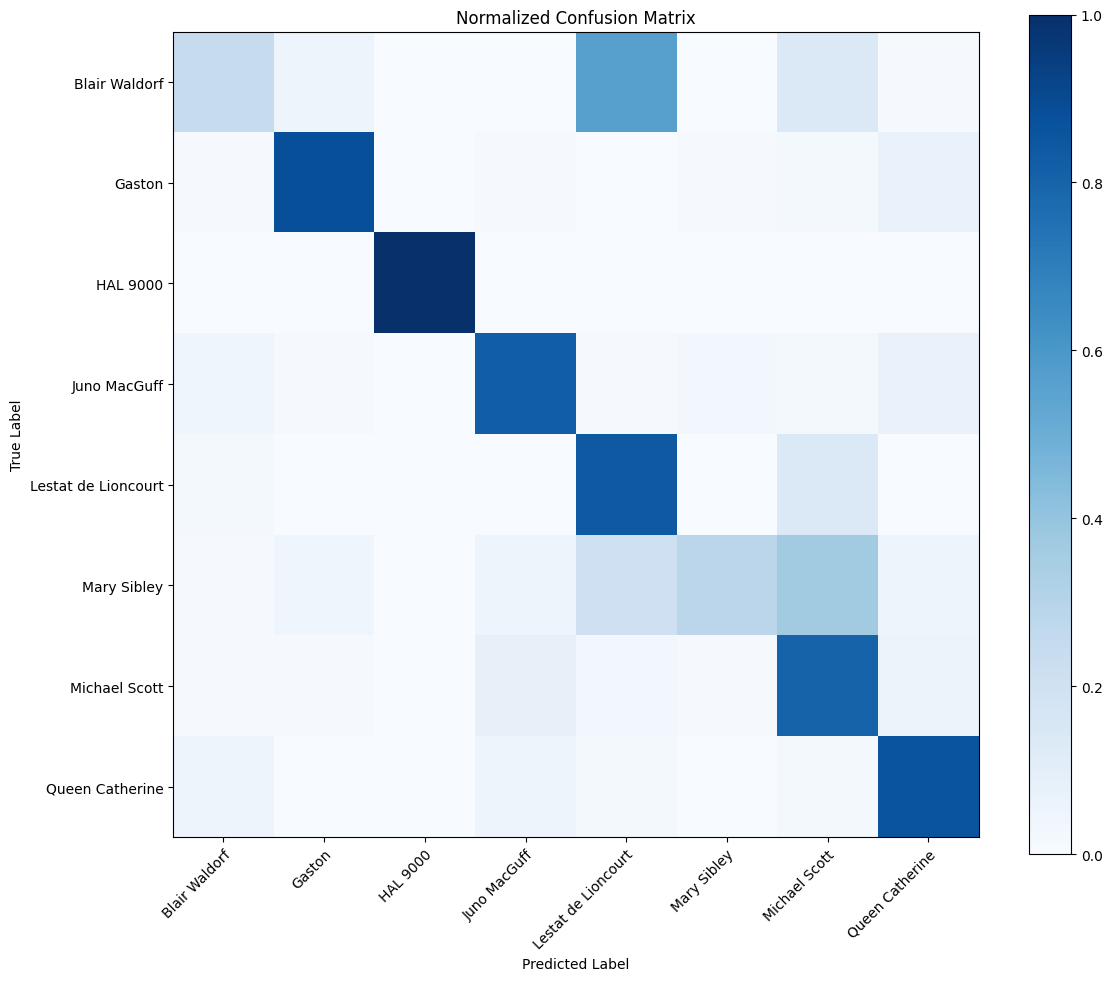

In [14]:
cfusion_matrix(df_1)

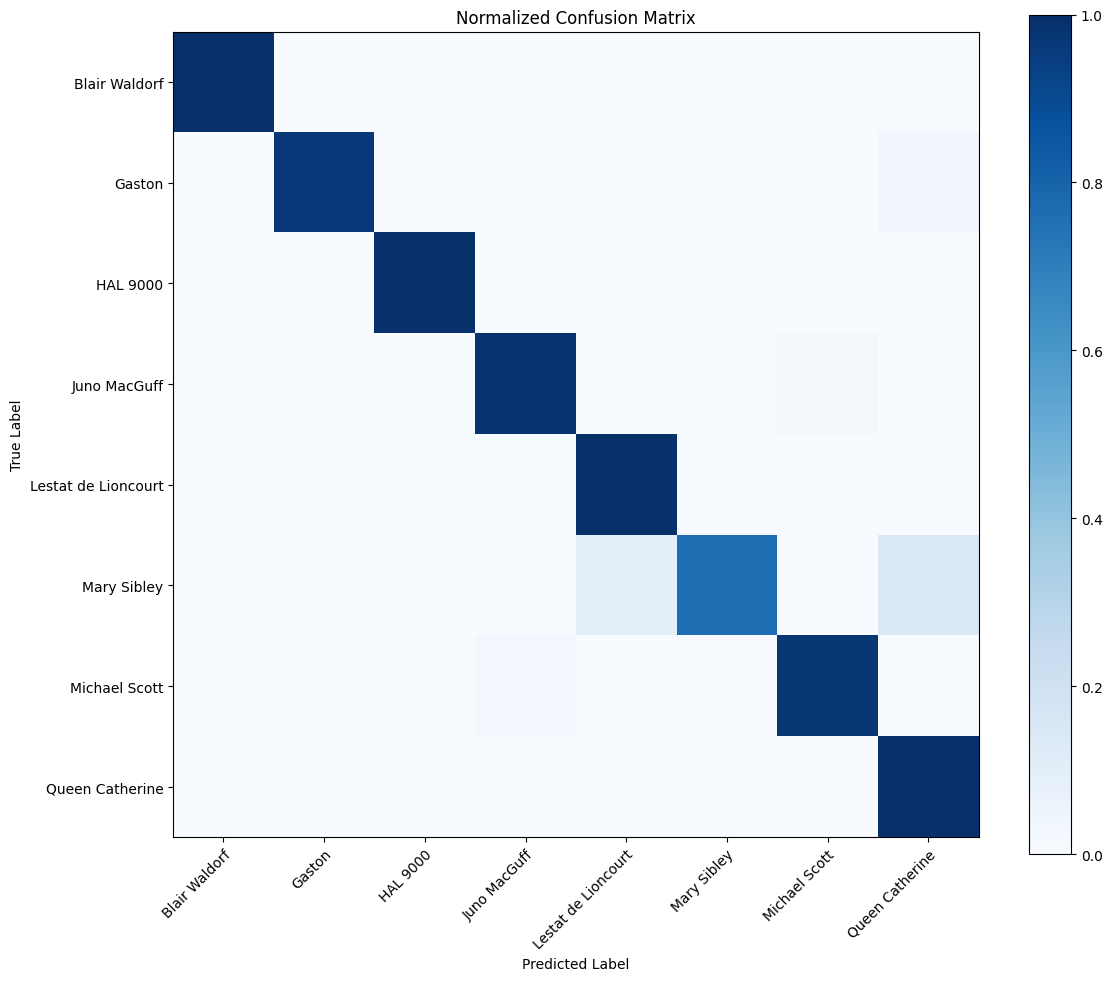

In [15]:
cfusion_matrix(df_2)